In [61]:
import pandas as pd
df = pd.read_csv("/Users/dev/Desktop/graphCeylon-API/data/orchestrator/raw/dataset.csv")

In [62]:
print(df.head())


   id                                               text          intent  \
0   1  Plan a 2-day trip to Nuwara Eliya for a family...  plan_itinerary   
1   2  Create a 3-day itinerary covering Kandy and Si...  plan_itinerary   
2   3  Create a 7-day itinerary covering Mirissa and ...  plan_itinerary   
3   4  I need a 4-day eco friendly itinerary in Nuwar...  plan_itinerary   
4   5  Create a 7-day itinerary covering Ella and Kan...  plan_itinerary   

   split  
0  train  
1  train  
2  train  
3  train  
4  train  


In [63]:
print(df.shape)

(2200, 4)


In [64]:
print("\n=== Columns ===")
print(df.columns)

print("\n=== Intent distribution ===")
print(df['intent'].value_counts())

print("\n=== Split distribution ===")
print(df['split'].value_counts())

print("\n=== Sample examples ===")
print(df.sample(5))


=== Columns ===
Index(['id', 'text', 'intent', 'split'], dtype='object')

=== Intent distribution ===
intent
plan_itinerary         200
recommend_pois         200
modify_itinerary       200
crowd_forecast         200
info_attraction        200
info_accommodation     200
info_transport         200
info_visa_policy       200
update_preferences     200
explanation_request    200
generic_fact_query     200
Name: count, dtype: int64

=== Split distribution ===
split
train    1760
val       220
test      220
Name: count, dtype: int64

=== Sample examples ===
        id                                               text  \
1615  1616             From now on keep walking distances low   
1437  1438           Is ETA required for US passport holders?   
1581  1582  How long can I stay in Sri Lanka on a tourist ...   
428    429  Change my current itinerary to remove temples ...   
113    114  Can you design a 4-day Sri Lanka trip starting...   

                  intent  split  
1615  update_pr

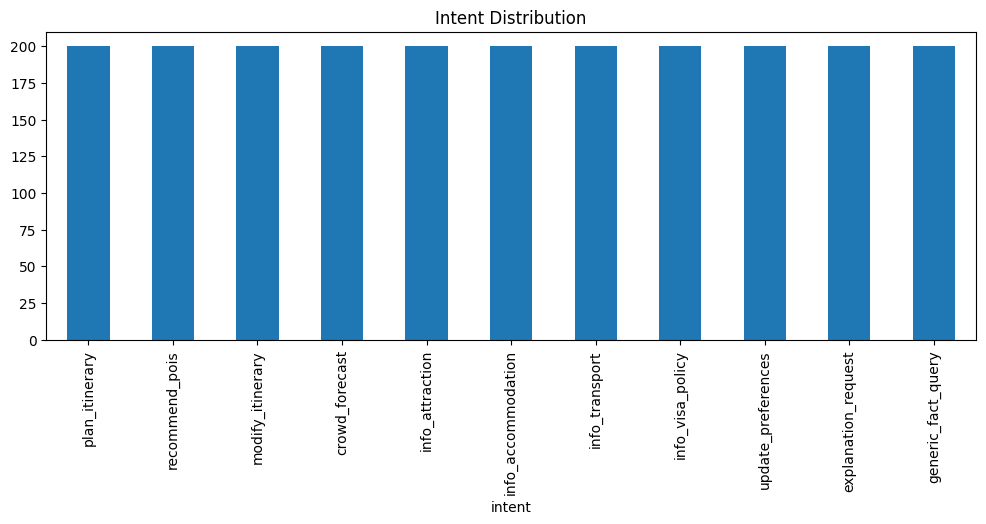

In [65]:
import matplotlib.pyplot as plt

df['intent'].value_counts().plot(kind='bar', figsize=(12,4))
plt.title("Intent Distribution")
plt.show()


In [66]:
dup_texts = df['text'][df['text'].duplicated()].unique()



In [67]:
df_duplicates = df[df['text'].isin(dup_texts)]
df_duplicates


,id,text,intent,split
3,4,I need a 4-day eco friendly itinerary in Nuwar...,plan_itinerary,train
11,12,I need a 6-day eco friendly itinerary in Galle...,plan_itinerary,train
12,13,I need a 5-day eco friendly itinerary in Kandy...,plan_itinerary,train
14,15,I need a 5-day eco friendly itinerary in Colom...,plan_itinerary,train
27,28,I need a 3-day eco friendly itinerary in Nuwar...,plan_itinerary,train
...,...,...,...,...
2193,2194,How is the weather in Galle in August?,generic_fact_query,test
2195,2196,What local customs should I know in Sri Lanka?,generic_fact_query,test
2196,2197,"Kandy august wala weather kohomada, honda da y...",generic_fact_query,test
2198,2199,"Kandy august wala weather kohomada, honda da y...",generic_fact_query,test


In [68]:
print("Before:", len(df))

df_no_exact_dups = df.drop_duplicates(subset=['text', 'intent']).reset_index(drop=True)

print("After :", len(df_no_exact_dups))
print("Removed exact duplicates:", len(df) - len(df_no_exact_dups))


Before: 2200
After : 801
Removed exact duplicates: 1399


In [69]:
# Count how many rows per intent after removing exact duplicates
intent_counts = df_no_exact_dups['intent'].value_counts().reset_index()

intent_counts.columns = ['intent', 'count']
print(intent_counts)


                 intent  count
0        plan_itinerary    168
1        recommend_pois    146
2        info_transport    137
3        crowd_forecast    106
4    info_accommodation     68
5       info_attraction     52
6    generic_fact_query     41
7   explanation_request     33
8      modify_itinerary     18
9    update_preferences     18
10     info_visa_policy     14


In [70]:
# Count how many rows per intent after removing exact duplicates
intent_counts = df_no_exact_dups['intent'].value_counts().reset_index()

intent_counts.columns = ['intent', 'count']

# Save to CSV
intent_counts.to_csv("Without_duplicates.csv", index=False)

print("Without_duplicates.csv")
print(intent_counts)


Without_duplicates.csv
                 intent  count
0        plan_itinerary    168
1        recommend_pois    146
2        info_transport    137
3        crowd_forecast    106
4    info_accommodation     68
5       info_attraction     52
6    generic_fact_query     41
7   explanation_request     33
8      modify_itinerary     18
9    update_preferences     18
10     info_visa_policy     14


In [71]:
# After running:
# df_no_exact_dups = df.drop_duplicates(subset=['text', 'intent']).reset_index(drop=True)

# Save cleaned dataset to CSV
df_no_exact_dups.to_csv("dataset_no_dups.csv", index=False)

print("dataset_no_dups.csv")


dataset_no_dups.csv


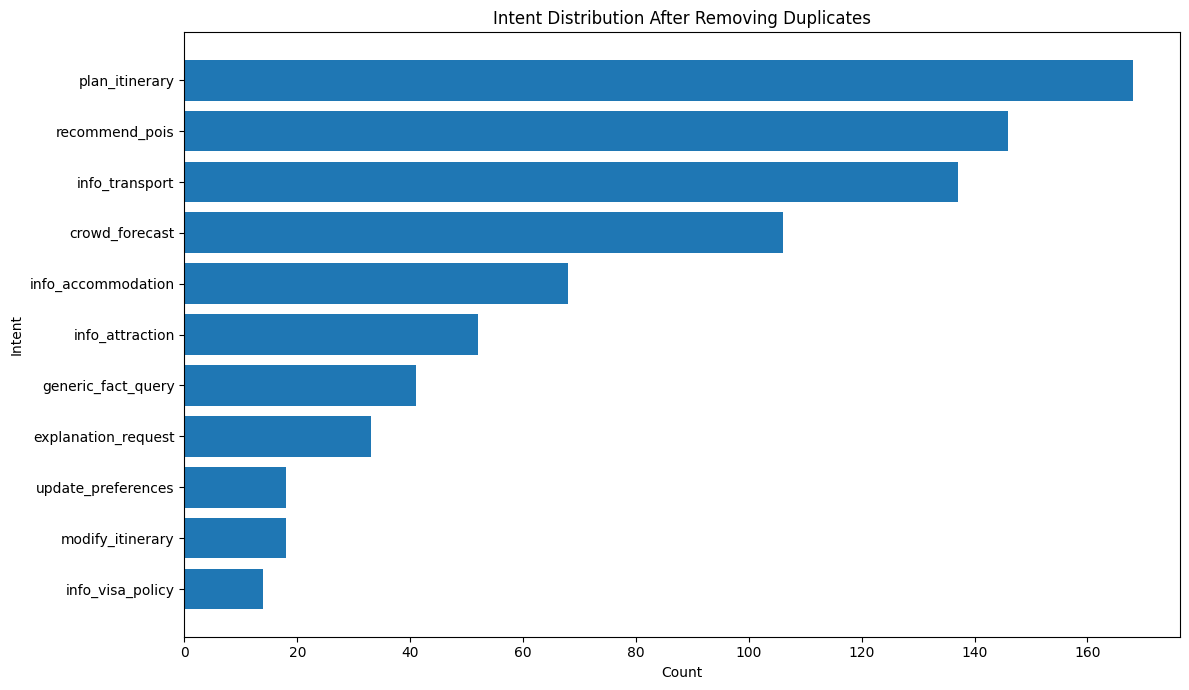

In [72]:
import pandas as pd
import matplotlib.pyplot as plt

# Load full dataset (after removing duplicates)
df = pd.read_csv("dataset_no_dups.csv")

# Step 1: Compute counts per intent
intent_counts = df['intent'].value_counts().reset_index()
intent_counts.columns = ['intent', 'count']

# Step 2: Sort by count (optional, recommended)
intent_counts = intent_counts.sort_values("count", ascending=True)

# Step 3: Plot
plt.figure(figsize=(12, 7))
plt.barh(intent_counts["intent"], intent_counts["count"])
plt.xlabel("Count")
plt.ylabel("Intent")
plt.title("Intent Distribution After Removing Duplicates")
plt.tight_layout()
plt.show()



In [73]:
df[df.duplicated('text', keep=False)]


,id,text,intent,split


In [74]:
import pandas as pd

df = pd.read_csv("/Users/dev/Desktop/graphCeylon-API/data/orchestrator/raw/datasetV1.csv")
len(df)



871

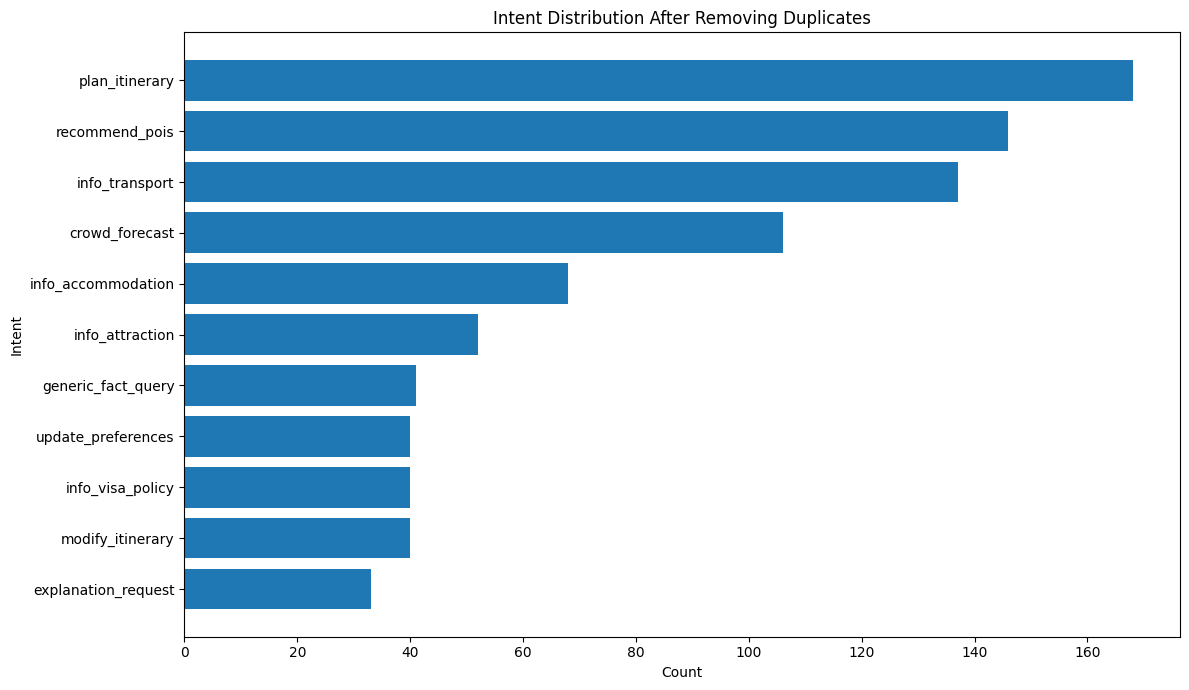

In [75]:
# Step 1: Compute counts per intent
intent_counts = df['intent'].value_counts().reset_index()
intent_counts.columns = ['intent', 'count']

# Step 2: Sort by count (optional, recommended)
intent_counts = intent_counts.sort_values("count", ascending=True)

# Step 3: Plot
plt.figure(figsize=(12, 7))
plt.barh(intent_counts["intent"], intent_counts["count"])
plt.xlabel("Count")
plt.ylabel("Intent")
plt.title("Intent Distribution After Removing Duplicates")
plt.tight_layout()
plt.show()

In [76]:
df = pd.read_csv("/Users/dev/Desktop/graphCeylon-API/data/orchestrator/raw/datasetV1.csv")

# Count rows per intent
intent_counts = df['intent'].value_counts()

print(intent_counts)

intent
plan_itinerary         168
recommend_pois         146
info_transport         137
crowd_forecast         106
info_accommodation      68
info_attraction         52
generic_fact_query      41
modify_itinerary        40
info_visa_policy        40
update_preferences      40
explanation_request     33
Name: count, dtype: int64


In [77]:
import pandas as pd

# Load your multi-label dataset
df = pd.read_csv("/Users/dev/Desktop/graphCeylon-API/data/orchestrator/raw/intents_multilabel.csv")

# If num_labels column does not exist, compute it
if "num_labels" not in df.columns:
    df["num_labels"] = df["labels"].apply(lambda s: len(str(s).split(";")))

print("=== Label Count Distribution ===")
print(df["num_labels"].value_counts().sort_index())

print("\n=== Percentage Distribution ===")
print((df["num_labels"].value_counts(normalize=True).sort_index() * 100).round(2))

# Optional: show examples with exactly 2 labels
print("\n=== Sample examples with exactly 2 labels ===")
print(df[df["num_labels"] == 2][["text", "labels"]].head(10))


=== Label Count Distribution ===
num_labels
1    1179
2    1182
3      16
4       1
Name: count, dtype: int64

=== Percentage Distribution ===
num_labels
1    49.58
2    49.71
3     0.67
4     0.04
Name: proportion, dtype: float64

=== Sample examples with exactly 2 labels ===
                                                  text  \
168  Give me a few budget attractions close to Nuwa...   
175  What are some romantic things to do near Colombo?   
176  Give me a few nature attractions close to Mirissa   
177  What are some quiet things to do near Nuwara E...   
181  What are some eco friendly things to do near S...   
182  Give me a few photography attractions close to...   
183  Give me a few family friendly attractions clos...   
184  What are some nature things to do near Trincom...   
185  What are some budget things to do near Trincom...   
189     Give me a few nature attractions close to Ella   

                             labels  
168  info_attraction;recommend_pois  
175  in

In [78]:
df[df["text"].str.contains("hotel", case=False)][["text", "labels"]].head(20)


,text,labels
492,Suggest luxury hotels in Trincomalee for a couple,info_accommodation
494,Suggest mid range hotels in Kandy for elderly ...,info_accommodation
495,What is the average price per night for a hote...,info_accommodation
496,What is the average price per night for a hote...,info_accommodation
497,Suggest luxury hotels in Mirissa for elderly p...,info_accommodation
499,Suggest strict hotels in Sigiriya for a family,info_accommodation
501,What is the average price per night for a hote...,info_accommodation
502,What is the average price per night for a hote...,info_accommodation
506,Suggest mid range hotels in Sigiriya for solo ...,info_accommodation
507,What is the average price per night for a hote...,info_accommodation


In [79]:
df[df["text"].str.contains("crowd|busy|packed|quiet", case=False)][["text", "labels"]].head(20)


,text,labels
172,Suggest quiet places near Nuwara Eliya for one...,recommend_pois
177,What are some quiet things to do near Nuwara E...,info_attraction;recommend_pois
216,Recommend some quiet spots around Ella for eld...,recommend_pois
225,What are some quiet things to do near Ella?,info_attraction;recommend_pois
237,Suggest quiet places near Mirissa for one day,recommend_pois
238,Suggest quiet places near Colombo for one day,recommend_pois
248,Suggest quiet places near Galle for one day,recommend_pois
256,Suggest quiet places near Kandy for one day,recommend_pois
257,Give me a few quiet attractions close to Nuwar...,info_attraction;recommend_pois
258,Recommend some quiet spots around Colombo for ...,recommend_pois


In [80]:
import pandas as pd

df = pd.read_csv("/Users/dev/Desktop/graphCeylon-API/data/orchestrator/raw/intents_multilabel.csv")

co_occurrence = {}

for labels in df["labels"]:
    labs = labels.split(";")
    for l1 in labs:
        for l2 in labs:
            if l1 == l2:
                continue
            co_occurrence[(l1, l2)] = co_occurrence.get((l1, l2), 0) + 1

# Sort by frequency
sorted_pairs = sorted(co_occurrence.items(), key=lambda x: x[1], reverse=True)

# Show top 20 co-occurrences
for pair, count in sorted_pairs[:20]:
    print(pair, count)


('plan_itinerary', 'forecast_weather') 306
('forecast_weather', 'plan_itinerary') 306
('crowd_forecast', 'recommend_pois') 305
('recommend_pois', 'crowd_forecast') 305
('plan_itinerary', 'crowd_forecast') 304
('crowd_forecast', 'plan_itinerary') 304
('info_attraction', 'recommend_pois') 66
('recommend_pois', 'info_attraction') 66
('info_visa_policy', 'forecast_weather') 58
('forecast_weather', 'info_visa_policy') 58
('info_accommodation', 'info_visa_policy') 29
('info_visa_policy', 'info_accommodation') 29
('crowd_forecast', 'forecast_weather') 22
('forecast_weather', 'crowd_forecast') 22
('forecast_sustainability', 'forecast_weather') 17
('forecast_weather', 'forecast_sustainability') 17
('forecast_price', 'forecast_weather') 16
('forecast_weather', 'forecast_price') 16
('crowd_forecast', 'update_preferences') 9
('update_preferences', 'crowd_forecast') 9


In [81]:
df.shape

(2378, 6)

In [82]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics import f1_score, classification_report, accuracy_score

from datasets import Dataset, DatasetDict

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
)
import torch


In [83]:
# Path to your multi-label dataset
CSV_PATH = "/Users/dev/Desktop/graphCeylon-API/data/orchestrator/raw/intents_multilabel.csv"

df = pd.read_csv(CSV_PATH)
print(df.head())
print(df.columns)
print(df.shape)


   id                                               text          intent  \
0   1  Plan a 2-day trip to Nuwara Eliya for a family...  plan_itinerary   
1   2  Create a 3-day itinerary covering Kandy and Si...  plan_itinerary   
2   3  Create a 7-day itinerary covering Mirissa and ...  plan_itinerary   
3   4  I need a 4-day eco friendly itinerary in Nuwar...  plan_itinerary   
4   5  Create a 7-day itinerary covering Ella and Kan...  plan_itinerary   

   split          labels  num_labels  
0  train  plan_itinerary           1  
1  train  plan_itinerary           1  
2  train  plan_itinerary           1  
3  train  plan_itinerary           1  
4  train  plan_itinerary           1  
Index(['id', 'text', 'intent', 'split', 'labels', 'num_labels'], dtype='object')
(2378, 6)


In [84]:
INTENT_LABELS = [
    # Planning & recommendation
    "plan_itinerary",
    "recommend_pois",
    "modify_itinerary",

    # Forecasting-related intents
    "crowd_forecast",
    "forecast_weather",
    "forecast_price",
    "forecast_sustainability",

    # Information-based intents
    "info_attraction",
    "info_accommodation",
    "info_transport",
    "info_visa_policy",

    # 🔹 Hotel transactional intents (NEW)
    "check_availability",
    "book_hotel",
    "modify_booking",
    "cancel_booking",

    # Preference & meta intents
    "update_preferences",
    "explanation_request",

    # General fallback
    "generic_fact_query"
]



num_labels = len(INTENT_LABELS)
label2id = {lbl: i for i, lbl in enumerate(INTENT_LABELS)}
id2label = {i: lbl for lbl, i in label2id.items()}

label2id, id2label


({'plan_itinerary': 0,
  'recommend_pois': 1,
  'modify_itinerary': 2,
  'crowd_forecast': 3,
  'forecast_weather': 4,
  'forecast_price': 5,
  'forecast_sustainability': 6,
  'info_attraction': 7,
  'info_accommodation': 8,
  'info_transport': 9,
  'info_visa_policy': 10,
  'check_availability': 11,
  'book_hotel': 12,
  'modify_booking': 13,
  'cancel_booking': 14,
  'update_preferences': 15,
  'explanation_request': 16,
  'generic_fact_query': 17},
 {0: 'plan_itinerary',
  1: 'recommend_pois',
  2: 'modify_itinerary',
  3: 'crowd_forecast',
  4: 'forecast_weather',
  5: 'forecast_price',
  6: 'forecast_sustainability',
  7: 'info_attraction',
  8: 'info_accommodation',
  9: 'info_transport',
  10: 'info_visa_policy',
  11: 'check_availability',
  12: 'book_hotel',
  13: 'modify_booking',
  14: 'cancel_booking',
  15: 'update_preferences',
  16: 'explanation_request',
  17: 'generic_fact_query'})

In [85]:
# Parse "labels" column: "plan_itinerary;info_accommodation" → ["plan_itinerary", "info_accommodation"]
def parse_labels(label_str):
    if pd.isna(label_str):
        return []
    return [x.strip() for x in str(label_str).split(";") if x.strip()]

df["label_list"] = df["labels"].apply(parse_labels)

# Use MultiLabelBinarizer to get multi-hot vectors
mlb = MultiLabelBinarizer(classes=INTENT_LABELS)
Y = mlb.fit_transform(df["label_list"])

print("Multi-hot shape:", Y.shape)
print("Example row:", df["text"].iloc[0], "→", df["label_list"].iloc[0], "→", Y[0])


Multi-hot shape: (2378, 18)
Example row: Plan a 2-day trip to Nuwara Eliya for a family with a low budget → ['plan_itinerary'] → [1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [86]:
intent_counts = df["intent"].value_counts()
print(intent_counts)


intent
plan_itinerary             786
recommend_pois             460
info_transport             143
crowd_forecast             121
info_accommodation         105
forecast_sustainability     94
forecast_weather            85
update_preferences          81
info_visa_policy            73
forecast_price              54
modify_itinerary            54
info_attraction             52
generic_fact_query          48
explanation_request         42
mixed                       40
cancel_booking              31
book_hotel                  30
modify_booking              30
check_availability          29
single                      20
Name: count, dtype: int64


In [87]:
df["intent"].value_counts()[df["intent"].value_counts() < 2]


Series([], Name: count, dtype: int64)

In [88]:
from sklearn.model_selection import train_test_split

df["label_list"] = df["labels"].apply(parse_labels)

# Create a stratify key: rare intents → "__RARE__"
counts = df["intent"].value_counts()
df["stratify_key"] = df["intent"].where(df["intent"].map(counts) >= 2, "__RARE__")

train_df, temp_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["stratify_key"]
)

# Repeat for val/test
counts2 = temp_df["intent"].value_counts()
temp_df["stratify_key"] = temp_df["intent"].where(temp_df["intent"].map(counts2) >= 2, "__RARE__")

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    random_state=42,
    stratify=temp_df["stratify_key"]
)

train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)

print("Train/Val/Test sizes:", len(train_df), len(val_df), len(test_df))
print("Train intent counts:\n", train_df["intent"].value_counts().tail(10))


Train/Val/Test sizes: 1902 238 238
Train intent counts:
 intent
forecast_price         43
info_attraction        42
generic_fact_query     38
explanation_request    34
mixed                  32
cancel_booking         25
book_hotel             24
modify_booking         24
check_availability     23
single                 16
Name: count, dtype: int64


In [89]:
from sklearn.preprocessing import MultiLabelBinarizer

mlb = MultiLabelBinarizer(classes=INTENT_LABELS)
mlb.fit([INTENT_LABELS])  # lock label order

Y_train = mlb.transform(train_df["label_list"])
Y_val   = mlb.transform(val_df["label_list"])
Y_test  = mlb.transform(test_df["label_list"])

print("Y_train:", Y_train.shape)
print("Y_val:", Y_val.shape)
print("Y_test:", Y_test.shape)


Y_train: (1902, 18)
Y_val: (238, 18)
Y_test: (238, 18)


In [90]:
# import pandas as pd
# import re

# # ✅ Update this if your path differs
# INPUT_CSV  = "/Users/dev/Desktop/graphCeylon-API/data/orchestrator/raw/intents_multilabel.csv"
# OUTPUT_CSV = "/Users/dev/Desktop/graphCeylon-API/data/orchestrator/raw/intents_multilabel.fixed.csv"

# INTENT_LABELS = [
#     "plan_itinerary",
#     "recommend_pois",
#     "modify_itinerary",
#     "crowd_forecast",
#     "forecast_weather",
#     "forecast_price",
#     "forecast_sustainability",
#     "info_attraction",
#     "info_accommodation",
#     "info_transport",
#     "info_visa_policy",
#     "check_availability",
#     "book_hotel",
#     "modify_booking",
#     "cancel_booking",
#     "update_preferences",
#     "explanation_request",
#     "generic_fact_query",
# ]
# VALID_LABELS = set(INTENT_LABELS)

# def parse_labels_anysep(label_str: str) -> list[str]:
#     """Split labels on ';' or '|' and clean whitespace."""
#     if pd.isna(label_str):
#         return []
#     s = str(label_str).strip()
#     if not s:
#         return []
#     parts = re.split(r"[;|]", s)
#     return [p.strip() for p in parts if p.strip()]

# def normalize_row_labels(labels_raw: str) -> tuple[str, list[str], list[str]]:
#     """
#     Returns:
#       - normalized labels string joined by ';'
#       - kept labels list
#       - dropped labels list (invalid)
#     """
#     labels_list = parse_labels_anysep(labels_raw)

#     # Deduplicate while preserving order
#     seen = set()
#     deduped = []
#     for lab in labels_list:
#         if lab not in seen:
#             seen.add(lab)
#             deduped.append(lab)

#     kept = [l for l in deduped if l in VALID_LABELS]
#     dropped = [l for l in deduped if l not in VALID_LABELS]

#     normalized = ";".join(kept)
#     return normalized, kept, dropped

# def main():
#     df = pd.read_csv(INPUT_CSV)

#     # Basic cleanup: strip common columns if present
#     for col in ["intent", "labels", "text", "split"]:
#         if col in df.columns:
#             df[col] = df[col].astype(str).str.strip()

#     # Fix "intent" spacing issues (e.g., " cancel_booking")
#     if "intent" in df.columns:
#         df["intent"] = df["intent"].str.strip()

#     # Normalize labels
#     dropped_map = {}
#     normalized_labels = []
#     label_lists = []
#     dropped_lists = []

#     for i, raw in enumerate(df.get("labels", pd.Series([""] * len(df)))):
#         norm, kept, dropped = normalize_row_labels(raw)
#         normalized_labels.append(norm)
#         label_lists.append(kept)
#         dropped_lists.append(dropped)

#         if dropped:
#             dropped_map[i] = dropped

#     if "labels" in df.columns:
#         df["labels"] = normalized_labels
#     else:
#         df["labels"] = normalized_labels

#     # Ensure num_labels is correct (if column exists, overwrite; else create)
#     df["num_labels"] = [len(x) for x in label_lists]

#     # Optional: ensure "intent" is included in labels for single-label rows
#     # (If your dataset expects intent == labels for many rows, this helps)
#     if "intent" in df.columns:
#         fixed_labels = []
#         fixed_lists = []
#         for intent, labs in zip(df["intent"], label_lists):
#             # If labels empty but intent exists and is valid, set labels=intent
#             if (not labs) and (intent in VALID_LABELS):
#                 labs = [intent]
#             # If intent is valid and not already in multi-label list, optionally add it
#             # Comment out if you don't want this behavior:
#             if intent in VALID_LABELS and intent not in labs:
#                 labs = labs + [intent]

#             # Deduplicate again
#             seen = set()
#             labs2 = []
#             for l in labs:
#                 if l not in seen:
#                     seen.add(l)
#                     labs2.append(l)

#             fixed_lists.append(labs2)
#             fixed_labels.append(";".join(labs2))

#         df["labels"] = fixed_labels
#         df["num_labels"] = [len(x) for x in fixed_lists]
#         label_lists = fixed_lists  # update

#     # Remove broken rows: missing text OR missing intent
#     if "text" in df.columns:
#         df["text"] = df["text"].astype(str)
#         bad_text = df["text"].str.strip().eq("") | df["text"].str.lower().eq("nan")
#     else:
#         bad_text = pd.Series([True] * len(df))

#     if "intent" in df.columns:
#         df["intent"] = df["intent"].astype(str)
#         bad_intent = df["intent"].str.strip().eq("") | df["intent"].str.lower().eq("nan")
#     else:
#         bad_intent = pd.Series([True] * len(df))

#     before = len(df)
#     df = df[~(bad_text | bad_intent)].copy()
#     after = len(df)

#     # Report issues
#     print(f"Rows before: {before}, after removing broken rows: {after}, removed: {before-after}")

#     # Show invalid labels summary
#     all_dropped = [lab for dropped in dropped_lists for lab in dropped]
#     if all_dropped:
#         s = pd.Series(all_dropped).value_counts()
#         print("\nInvalid labels found (and removed):")
#         print(s)
#     else:
#         print("\nNo invalid labels found.")

#     # Show intent counts (after strip)
#     if "intent" in df.columns:
#         print("\nIntent counts (top 30):")
#         print(df["intent"].value_counts().head(30))

#         # Show intents with <2 rows (these break stratify)
#         rare = df["intent"].value_counts()[df["intent"].value_counts() < 2]
#         print("\nIntents with <2 samples (will break stratify):")
#         print(rare if len(rare) else "None ✅")

#     # Save
#     df.to_csv(OUTPUT_CSV, index=False)
#     print(f"\nSaved cleaned file to: {OUTPUT_CSV}")

# if __name__ == "__main__":
#     main()


In [91]:
# Attach the multi-hot label vectors as a column
train_df = train_df.copy()
val_df   = val_df.copy()
test_df  = test_df.copy()

train_df["labels_vec"] = list(Y_train)
val_df["labels_vec"]   = list(Y_val)
test_df["labels_vec"]  = list(Y_test)

# Keep only necessary columns for training
train_df_small = train_df[["text", "labels_vec"]]
val_df_small   = val_df[["text", "labels_vec"]]
test_df_small  = test_df[["text", "labels_vec"]]

train_ds = Dataset.from_pandas(train_df_small)
val_ds   = Dataset.from_pandas(val_df_small)
test_ds  = Dataset.from_pandas(test_df_small)

dataset = DatasetDict({
    "train": train_ds,
    "validation": val_ds,
    "test": test_ds,
})

dataset


DatasetDict({
    train: Dataset({
        features: ['text', 'labels_vec'],
        num_rows: 1902
    })
    validation: Dataset({
        features: ['text', 'labels_vec'],
        num_rows: 238
    })
    test: Dataset({
        features: ['text', 'labels_vec'],
        num_rows: 238
    })
})

In [92]:
MODEL_NAME = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def preprocess_function(examples):
    # Tokenize the text
    encodings = tokenizer(
        examples["text"],
        padding="max_length",
        truncation=True,
        max_length=128,
    )
    # Attach labels
    encodings["labels"] = examples["labels_vec"]
    return encodings

encoded_dataset = dataset.map(preprocess_function, batched=True)
encoded_dataset




/Users/dev/Desktop/graphCeylon-API/services/orchestrator/.venv/lib/python3.12/site-packages/huggingface_hub/file_download.py:942: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Map: 100%|██████████| 238/238 [00:00<00:00, 19999.69 examples/s]


DatasetDict({
    train: Dataset({
        features: ['text', 'labels_vec', 'input_ids', 'attention_mask', 'labels'],
        num_rows: 1902
    })
    validation: Dataset({
        features: ['text', 'labels_vec', 'input_ids', 'attention_mask', 'labels'],
        num_rows: 238
    })
    test: Dataset({
        features: ['text', 'labels_vec', 'input_ids', 'attention_mask', 'labels'],
        num_rows: 238
    })
})

In [93]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=num_labels,
    problem_type="multi_label_classification",
    id2label=id2label,
    label2id=label2id,
)


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [94]:
from scipy.special import expit  # sigmoid

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    # Apply sigmoid to get probabilities
    probs = expit(logits)
    
    # Choose threshold
    threshold = 0.5
    preds = (probs >= threshold).astype(int)

    # Micro-F1 (overall)
    micro_f1 = f1_score(labels, preds, average="micro", zero_division=0)
    # Macro-F1 (per-label average)
    macro_f1 = f1_score(labels, preds, average="macro", zero_division=0)

    # Subset accuracy: exact match of all labels
    subset_acc = accuracy_score(labels, preds)

    metrics = {
        "micro_f1": micro_f1,
        "macro_f1": macro_f1,
        "subset_accuracy": subset_acc,
    }
    return metrics


In [95]:
def preprocess_function(examples):
    # Tokenize text
    encodings = tokenizer(
        examples["text"],
        padding="max_length",
        truncation=True,
        max_length=128,
    )
    
    # Convert labels_vec → float32
    # examples["labels_vec"] is a list of lists / arrays like [[0,1,0,...], [1,0,0,...], ...]
    labels = examples["labels_vec"]
    encodings["labels"] = [[float(x) for x in row] for row in labels]
    
    return encodings


In [96]:
encoded_dataset = dataset.map(preprocess_function, batched=True)


Map: 100%|██████████| 238/238 [00:00<00:00, 18309.36 examples/s]


In [97]:
from transformers import TrainingArguments, Trainer

batch_size = 8  # or 4 if needed

training_args = TrainingArguments(
    output_dir="distilbert-multilabel-intent",
    evaluation_strategy="epoch",   # <-- FIXED
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=batch_size,
    per_device_eval_batch_size=batch_size,
    num_train_epochs=8,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    logging_steps=20,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=encoded_dataset["train"],
    eval_dataset=encoded_dataset["validation"],
    tokenizer=tokenizer,
    compute_metrics=compute_metrics,
)

trainer.train()


/Users/dev/Desktop/graphCeylon-API/services/orchestrator/.venv/lib/python3.12/site-packages/accelerate/accelerator.py:436: FutureWarning: Passing the following arguments to `Accelerator` is deprecated and will be removed in version 1.0 of Accelerate: dict_keys(['dispatch_batches', 'split_batches', 'even_batches', 'use_seedable_sampler']). Please pass an `accelerate.DataLoaderConfiguration` instead: 
dataloader_config = DataLoaderConfiguration(dispatch_batches=None, split_batches=False, even_batches=True, use_seedable_sampler=True)
  warnings.warn(
  0%|          | 0/1904 [00:00<?, ?it/s]/Users/dev/Desktop/graphCeylon-API/services/orchestrator/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:692: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  warnings.warn(warn_msg)
  1%|          | 21/1904 [00:04<05:04,  6.19it/s]

{'loss': 0.5909, 'grad_norm': 0.9122883677482605, 'learning_rate': 1.9789915966386557e-05, 'epoch': 0.08}


  2%|▏         | 41/1904 [00:07<05:20,  5.81it/s]

{'loss': 0.4309, 'grad_norm': 0.7418360114097595, 'learning_rate': 1.957983193277311e-05, 'epoch': 0.17}


  3%|▎         | 61/1904 [00:11<05:38,  5.44it/s]

...

                                                   
100%|██████████| 1904/1904 [05:46<00:00,  6.43it/s]

{'eval_loss': 0.021909017115831375, 'eval_micro_f1': 0.9673758865248226, 'eval_macro_f1': 0.8819020316861974, 'eval_subset_accuracy': 0.9159663865546218, 'eval_runtime': 1.2312, 'eval_samples_per_second': 193.315, 'eval_steps_per_second': 24.367, 'epoch': 8.0}


100%|██████████| 1904/1904 [05:50<00:00,  5.44it/s]

{'train_runtime': 350.0858, 'train_samples_per_second': 43.464, 'train_steps_per_second': 5.439, 'train_loss': 0.07151412780733168, 'epoch': 8.0}


TrainOutput(global_step=1904, training_loss=0.07151412780733168, metrics={'train_runtime': 350.0858, 'train_samples_per_second': 43.464, 'train_steps_per_second': 5.439, 'train_loss': 0.07151412780733168, 'epoch': 8.0})

In [98]:
from pathlib import Path

SAVE_DIR = Path("/Users/dev/Desktop/graphCeylon-API/models/orchestrator/intent_multilabel_final")

trainer.save_model(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)


('/Users/dev/Desktop/graphCeylon-API/models/orchestrator/intent_multilabel_final/tokenizer_config.json',
 '/Users/dev/Desktop/graphCeylon-API/models/orchestrator/intent_multilabel_final/special_tokens_map.json',
 '/Users/dev/Desktop/graphCeylon-API/models/orchestrator/intent_multilabel_final/vocab.txt',
 '/Users/dev/Desktop/graphCeylon-API/models/orchestrator/intent_multilabel_final/added_tokens.json',
 '/Users/dev/Desktop/graphCeylon-API/models/orchestrator/intent_multilabel_final/tokenizer.json')

In [99]:
test_metrics = trainer.evaluate(encoded_dataset["test"])
test_metrics


/Users/dev/Desktop/graphCeylon-API/services/orchestrator/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:692: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  warnings.warn(warn_msg)
100%|██████████| 30/30 [00:01<00:00, 23.53it/s]


{'eval_loss': 0.022437388077378273,
 'eval_micro_f1': 0.9713467048710601,
 'eval_macro_f1': 0.8860586457629125,
 'eval_subset_accuracy': 0.9243697478991597,
 'eval_runtime': 1.7231,
 'eval_samples_per_second': 138.126,
 'eval_steps_per_second': 17.411,
 'epoch': 8.0}

In [100]:
# Get raw predictions on test set
raw_preds = trainer.predict(encoded_dataset["test"])
logits = raw_preds.predictions
labels_true = raw_preds.label_ids

probs = expit(logits)
threshold = 0.5
preds = (probs >= threshold).astype(int)

print("Micro F1:", f1_score(labels_true, preds, average="micro", zero_division=0))
print("Macro F1:", f1_score(labels_true, preds, average="macro", zero_division=0))

# Per-label F1
for i, label_name in id2label.items():
    f1 = f1_score(labels_true[:, i], preds[:, i], average="binary", zero_division=0)
    support = labels_true[:, i].sum()
    print(f"{label_name:20s} F1 = {f1:.3f} (support={support})")


/Users/dev/Desktop/graphCeylon-API/services/orchestrator/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:692: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  warnings.warn(warn_msg)
100%|██████████| 30/30 [00:01<00:00, 25.93it/s]

Micro F1: 0.9713467048710601
Macro F1: 0.8860586457629125
plan_itinerary       F1 = 1.000 (support=79.0)
recommend_pois       F1 = 0.978 (support=47.0)
modify_itinerary     F1 = 0.909 (support=6.0)
crowd_forecast       F1 = 0.980 (support=75.0)
forecast_weather     F1 = 1.000 (support=46.0)
forecast_price       F1 = 0.889 (support=5.0)
forecast_sustainability F1 = 0.947 (support=10.0)
info_attraction      F1 = 0.917 (support=13.0)
info_accommodation   F1 = 0.923 (support=14.0)
info_transport       F1 = 0.968 (support=16.0)
info_visa_policy     F1 = 0.971 (support=18.0)
check_availability   F1 = 0.800 (support=3.0)
book_hotel           F1 = 0.000 (support=3.0)
modify_booking       F1 = 1.000 (support=3.0)
cancel_booking       F1 = 1.000 (support=3.0)
update_preferences   F1 = 1.000 (support=8.0)
explanation_request  F1 = 0.667 (support=4.0)
generic_fact_query   F1 = 1.000 (support=5.0)


In [101]:
from scipy.special import expit
import numpy as np
import torch

def predict_intents_safe(text, threshold=0.2, top_k_if_empty=2):
    model.eval()
    
    device = next(model.parameters()).device

    with torch.no_grad():
        inputs = tokenizer(
            text,
            return_tensors="pt",
            truncation=True,
            padding=True,
            max_length=128,
        )
        inputs = {k: v.to(device) for k, v in inputs.items()}

        outputs = model(**inputs)
        logits = outputs.logits.detach().cpu().numpy()
        probs = expit(logits)[0]

    # First pass: strict threshold
    pred_indices = np.where(probs >= threshold)[0]

    # If nothing passes threshold, pick the top-k labels instead
    if len(pred_indices) == 0 and top_k_if_empty is not None:
        top_indices = probs.argsort()[-top_k_if_empty:][::-1]
        pred_indices = top_indices

    pred_labels = [id2label[i] for i in pred_indices]

    # 🔹 POST-PROCESSING: force recommend_pois if the text clearly asks for recommendations
    text_lower = text.lower()
    recommend_triggers = [
        "suggest the best places",
        "best places to visit",
        "recommend places",
        "recommend some places",
        "recommend some nature spots",
        "show me places to visit",
        "show me family-friendly places",
        "suggest some places",
        "can you suggest the best places",
        "where should i go",
    ]

    if any(p in text_lower for p in recommend_triggers):
        if "recommend_pois" not in pred_labels:
            pred_labels.append("recommend_pois")

    return {
        "text": text,
        "probs": {id2label[i]: float(probs[i]) for i in range(len(probs))},
        "predicted_labels": pred_labels,
    }


In [102]:
import pandas as pd

df = pd.read_csv("/Users/dev/Desktop/graphCeylon-API/data/orchestrator/raw/intents_multilabel.csv")

print(df.head(10))          # First 10 rows
print(df.tail(10))          # Last 10 rows
print(df.columns)           # Column names
print(df.shape)             # Number of rows, columns
df.info()                   # Data types, null values


   id                                               text          intent  \
0   1  Plan a 2-day trip to Nuwara Eliya for a family...  plan_itinerary   
1   2  Create a 3-day itinerary covering Kandy and Si...  plan_itinerary   
2   3  Create a 7-day itinerary covering Mirissa and ...  plan_itinerary   
3   4  I need a 4-day eco friendly itinerary in Nuwar...  plan_itinerary   
4   5  Create a 7-day itinerary covering Ella and Kan...  plan_itinerary   
5   6  Can you design a 7-day Sri Lanka trip starting...  plan_itinerary   
6   7  Create a 5-day itinerary covering Mirissa and ...  plan_itinerary   
7   8  Can you design a 4-day Sri Lanka trip starting...  plan_itinerary   
8   9  Create a 3-day itinerary covering Nuwara Eliya...  plan_itinerary   
9  10  Plan a 2-day trip to Galle for a group of frie...  plan_itinerary   

   split          labels  num_labels  
0  train  plan_itinerary           1  
1  train  plan_itinerary           1  
2  train  plan_itinerary           1  
3  trai

In [103]:
df['labels_list'] = df['labels'].apply(lambda x: x.split(';'))
all_labels = df['labels_list'].explode()

print(all_labels.value_counts())


labels_list
plan_itinerary             790
crowd_forecast             765
forecast_weather           495
recommend_pois             468
info_visa_policy           163
info_transport             152
info_attraction            127
info_accommodation         126
forecast_sustainability    100
update_preferences          85
forecast_price              60
modify_itinerary            54
generic_fact_query          48
explanation_request         42
cancel_booking              31
book_hotel                  30
modify_booking              30
check_availability          29
Name: count, dtype: int64


In [104]:
df[df.duplicated(subset=['text'], keep=False)]


,id,text,intent,split,labels,num_labels,labels_list
701,1419,Do US citizens need a visa for Sri Lanka?,info_visa_policy,train,info_visa_policy,1,[info_visa_policy]
1262,2731,Do US citizens need a visa for Sri Lanka?,single,train,info_visa_policy,1,[info_visa_policy]
1359,2828,Plan a 3-day itinerary in Ella and also show m...,plan_itinerary,train,plan_itinerary;crowd_forecast,2,"[plan_itinerary, crowd_forecast]"
1360,2829,Create an itinerary for Colombo for 2 days as ...,plan_itinerary,train,plan_itinerary;crowd_forecast,2,"[plan_itinerary, crowd_forecast]"
1362,2831,Plan a 2-day itinerary in Ella as well as show...,plan_itinerary,train,plan_itinerary;crowd_forecast,2,"[plan_itinerary, crowd_forecast]"
...,...,...,...,...,...,...,...
2253,3722,Suggest attractions in Ella along with include...,recommend_pois,train,recommend_pois;crowd_forecast,2,"[recommend_pois, crowd_forecast]"
2254,3723,Suggest attractions in Colombo plus include ex...,recommend_pois,train,recommend_pois;crowd_forecast,2,"[recommend_pois, crowd_forecast]"
2255,3724,Recommend places to visit in Kandy along with ...,recommend_pois,train,recommend_pois;crowd_forecast,2,"[recommend_pois, crowd_forecast]"
2256,3725,Suggest attractions in Ella plus include expec...,recommend_pois,train,recommend_pois;crowd_forecast,2,"[recommend_pois, crowd_forecast]"


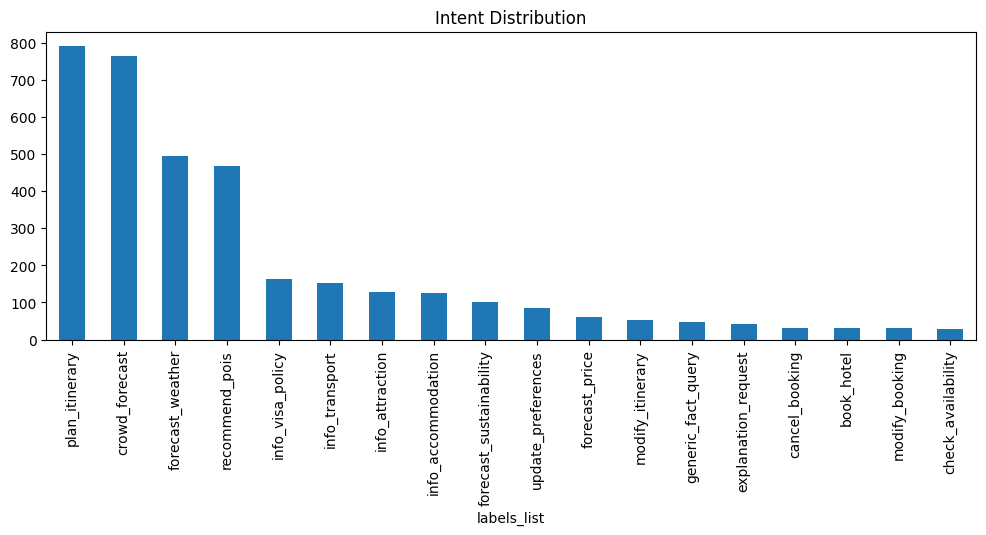

In [105]:
import matplotlib.pyplot as plt

all_labels.value_counts().plot(kind='bar', figsize=(12,4))
plt.title("Intent Distribution")
plt.show()


In [106]:
multi = df[df['labels'].str.contains(';')]
print(multi.head(10))
print("Number of multi-label rows:", len(multi))


      id                                               text          intent  \
168  201  Give me a few budget attractions close to Nuwa...  recommend_pois   
175  208  What are some romantic things to do near Colombo?  recommend_pois   
176  209  Give me a few nature attractions close to Mirissa  recommend_pois   
177  210  What are some quiet things to do near Nuwara E...  recommend_pois   
181  214  What are some eco friendly things to do near S...  recommend_pois   
182  215  Give me a few photography attractions close to...  recommend_pois   
183  216  Give me a few family friendly attractions clos...  recommend_pois   
184  218  What are some nature things to do near Trincom...  recommend_pois   
185  219  What are some budget things to do near Trincom...  recommend_pois   
189  223     Give me a few nature attractions close to Ella  recommend_pois   

     split                          labels  num_labels  \
168  train  info_attraction;recommend_pois           2   
175  train  in

In [107]:
import numpy as np

Yt = np.array(encoded_dataset["train"]["labels"])
print("Yt shape:", Yt.shape)
print("unique values:", np.unique(Yt)[:10])
print("positives per row min/mean/max:", Yt.sum(1).min(), Yt.sum(1).mean(), Yt.sum(1).max())
print("positive rate per label:", Yt.mean(0))
print("rows with 0 labels:", (Yt.sum(1) == 0).sum(), "/", len(Yt))


Yt shape: (1902, 18)
unique values: [0. 1.]
positives per row min/mean/max: 1.0 1.5115667718191377 4.0
positive rate per label: [0.33228181 0.19663512 0.02260778 0.32439537 0.20715037 0.02523659
 0.04206099 0.053102   0.05205047 0.06414301 0.06834911 0.01209253
 0.0126183  0.0126183  0.01314406 0.03522608 0.01787592 0.01997897]
rows with 0 labels: 0 / 1902


In [108]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MultiLabelBinarizer

df = pd.read_csv("/Users/dev/Desktop/graphCeylon-API/data/orchestrator/raw/intents_multilabel.csv")

INTENT_LABELS = [
    "plan_itinerary","recommend_pois","modify_itinerary",
    "crowd_forecast","forecast_weather","forecast_price","forecast_sustainability",
    "info_attraction","info_accommodation","info_transport","info_visa_policy",
    "update_preferences","explanation_request","generic_fact_query"
]
allowed = set(INTENT_LABELS)

def parse_labels(label_str):
    if pd.isna(label_str):
        return []
    return [x.strip() for x in str(label_str).split(";") if x.strip()]

df["label_list"] = df["labels"].apply(parse_labels)

mlb = MultiLabelBinarizer(classes=INTENT_LABELS)
Y = mlb.fit_transform(df["label_list"])
row_sum = Y.sum(axis=1)

bad = df[row_sum == 0].copy()
good = df[row_sum > 0].copy()
print("Total:", len(df))
print("Good :", len(good))
print("Bad  :", len(bad))


Total: 2378
Good : 2258
Bad  : 120


/Users/dev/Desktop/graphCeylon-API/services/orchestrator/.venv/lib/python3.12/site-packages/sklearn/preprocessing/_label.py:909: UserWarning: unknown class(es) ['book_hotel', 'cancel_booking', 'check_availability', 'modify_booking'] will be ignored
  warnings.warn(


In [109]:
import re
import pandas as pd

def parse_labels(label_str):
    if pd.isna(label_str):
        return []
    s = str(label_str).strip()
    if not s:
        return []
    # split on ; or | or , (any of them)
    parts = re.split(r"[;|,]+", s)
    return [p.strip() for p in parts if p.strip()]


In [110]:
df["label_list"] = df["labels"].apply(parse_labels)

mlb = MultiLabelBinarizer(classes=INTENT_LABELS)
Y = mlb.fit_transform(df["label_list"])
row_sum = Y.sum(axis=1)

print("Zero-label rows:", int((row_sum == 0).sum()), "/", len(df))
print("positives/row mean:", row_sum.mean())


Zero-label rows: 120 / 2378
positives/row mean: 1.4613120269133726


In [111]:
import pandas as pd
import re

CSV_PATH = "/Users/dev/Desktop/graphCeylon-API/data/orchestrator/raw/intents_multilabel.csv"

INTENT_LABELS = [
    "plan_itinerary","recommend_pois","modify_itinerary",
    "crowd_forecast","forecast_weather","forecast_price","forecast_sustainability",
    "info_attraction","info_accommodation","info_transport","info_visa_policy",
    "update_preferences","explanation_request","generic_fact_query"
]
allowed = set(INTENT_LABELS)

def parse_labels(label_str):
    if pd.isna(label_str):
        return []
    s = str(label_str).strip()
    if not s:
        return []
    parts = re.split(r"[;|,]+", s)
    return [p.strip() for p in parts if p.strip()]

df = pd.read_csv(CSV_PATH)
df["label_list"] = df["labels"].apply(parse_labels)
print("Rows:", len(df))


Rows: 2378


In [112]:
def unknown_labels(labs):
    return [l for l in labs if l not in allowed]

df["unknown"] = df["label_list"].apply(unknown_labels)

bad_unknown = df[df["unknown"].apply(len) > 0]
print("Rows with unknown labels:", len(bad_unknown))
print(bad_unknown["unknown"].explode().value_counts().head(30))


Rows with unknown labels: 120
unknown
cancel_booking        31
book_hotel            30
modify_booking        30
check_availability    29
Name: count, dtype: int64


In [113]:
import re
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics import f1_score, accuracy_score

from datasets import Dataset, DatasetDict
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
)

from scipy.special import expit
from pathlib import Path
import torch

CSV_PATH = "/Users/dev/Desktop/graphCeylon-API/data/orchestrator/raw/intents_multilabel.csv"

INTENT_LABELS = [
    "plan_itinerary","recommend_pois","modify_itinerary",
    "crowd_forecast","forecast_weather","forecast_price","forecast_sustainability",
    "info_attraction","info_accommodation","info_transport","info_visa_policy",
    "update_preferences","explanation_request","generic_fact_query"
]
allowed = set(INTENT_LABELS)

def parse_labels(label_str):
    """
    Supports: 'a;b', 'a|b', 'a,b', or mixed.
    Returns ONLY known labels from INTENT_LABELS.
    """
    if pd.isna(label_str):
        return []
    s = str(label_str).strip()
    if not s:
        return []
    parts = re.split(r"[;|,]+", s)
    labs = [p.strip() for p in parts if p.strip()]
    labs = [l for l in labs if l in allowed]
    return labs


In [114]:
df = pd.read_csv(CSV_PATH)

df["label_list"] = df["labels"].apply(parse_labels)

mlb = MultiLabelBinarizer(classes=INTENT_LABELS)
Y = mlb.fit_transform(df["label_list"])
row_sum = Y.sum(axis=1)

print("Total rows:", len(df))
print("Zero-label rows:", int((row_sum == 0).sum()), "/", len(df))
print("Avg labels per row:", float(row_sum.mean()))
print("Per-label positive rate:", (Y.mean(axis=0)).round(4))


Total rows: 2378
Zero-label rows: 120 / 2378
Avg labels per row: 1.4613120269133726
Per-label positive rate: [0.3322 0.1968 0.0227 0.3217 0.2082 0.0252 0.0421 0.0534 0.053  0.0639
 0.0685 0.0357 0.0177 0.0202]


In [115]:
# Stratify by primary intent column to keep balance
train_df, temp_df = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df["intent"]
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.5, random_state=42, stratify=temp_df["intent"]
)

Y_train = mlb.transform(train_df["label_list"])
Y_val   = mlb.transform(val_df["label_list"])
Y_test  = mlb.transform(test_df["label_list"])

# Convert to float32 lists (HF Trainer expects floats for multi-label)
train_df = train_df.copy()
val_df   = val_df.copy()
test_df  = test_df.copy()

train_df["labels_vec"] = [y.astype("float32").tolist() for y in Y_train]
val_df["labels_vec"]   = [y.astype("float32").tolist() for y in Y_val]
test_df["labels_vec"]  = [y.astype("float32").tolist() for y in Y_test]

dataset = DatasetDict({
    "train": Dataset.from_pandas(train_df[["text", "labels_vec"]]),
    "validation": Dataset.from_pandas(val_df[["text", "labels_vec"]]),
    "test": Dataset.from_pandas(test_df[["text", "labels_vec"]]),
})

dataset


DatasetDict({
    train: Dataset({
        features: ['text', 'labels_vec', '__index_level_0__'],
        num_rows: 1902
    })
    validation: Dataset({
        features: ['text', 'labels_vec', '__index_level_0__'],
        num_rows: 238
    })
    test: Dataset({
        features: ['text', 'labels_vec', '__index_level_0__'],
        num_rows: 238
    })
})

In [116]:
MODEL_NAME = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def preprocess_function(examples):
    enc = tokenizer(
        examples["text"],
        padding="max_length",
        truncation=True,
        max_length=128,
    )
    enc["labels"] = examples["labels_vec"]
    return enc

encoded_dataset = dataset.map(preprocess_function, batched=True)
encoded_dataset


/Users/dev/Desktop/graphCeylon-API/services/orchestrator/.venv/lib/python3.12/site-packages/huggingface_hub/file_download.py:942: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Map: 100%|██████████| 238/238 [00:00<00:00, 20735.42 examples/s]


DatasetDict({
    train: Dataset({
        features: ['text', 'labels_vec', '__index_level_0__', 'input_ids', 'attention_mask', 'labels'],
        num_rows: 1902
    })
    validation: Dataset({
        features: ['text', 'labels_vec', '__index_level_0__', 'input_ids', 'attention_mask', 'labels'],
        num_rows: 238
    })
    test: Dataset({
        features: ['text', 'labels_vec', '__index_level_0__', 'input_ids', 'attention_mask', 'labels'],
        num_rows: 238
    })
})

In [117]:
id2label = {i: l for i, l in enumerate(INTENT_LABELS)}
label2id = {l: i for i, l in enumerate(INTENT_LABELS)}

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(INTENT_LABELS),
    problem_type="multi_label_classification",
    id2label=id2label,
    label2id=label2id,
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    probs = expit(logits)
    preds = (probs >= 0.5).astype(int)

    return {
        "micro_f1": f1_score(labels, preds, average="micro", zero_division=0),
        "macro_f1": f1_score(labels, preds, average="macro", zero_division=0),
        "subset_accuracy": accuracy_score(labels, preds),
    }


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [119]:
training_args = TrainingArguments(
    output_dir="distilbert-multilabel-intent-run",

    evaluation_strategy="epoch",
    save_strategy="epoch",

    # ✅ keep only the latest checkpoint (prevents disk filling)
    save_total_limit=1,

    # ✅ saves smaller/avoids safetensors writer issues when disk is tight
    save_safetensors=False,

    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=8,
    weight_decay=0.01,

    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,

    logging_steps=20,
)


trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=encoded_dataset["train"],
    eval_dataset=encoded_dataset["validation"],
    tokenizer=tokenizer,
    compute_metrics=compute_metrics,
)

trainer.train()


/Users/dev/Desktop/graphCeylon-API/services/orchestrator/.venv/lib/python3.12/site-packages/accelerate/accelerator.py:436: FutureWarning: Passing the following arguments to `Accelerator` is deprecated and will be removed in version 1.0 of Accelerate: dict_keys(['dispatch_batches', 'split_batches', 'even_batches', 'use_seedable_sampler']). Please pass an `accelerate.DataLoaderConfiguration` instead: 
dataloader_config = DataLoaderConfiguration(dispatch_batches=None, split_batches=False, even_batches=True, use_seedable_sampler=True)
  warnings.warn(
/Users/dev/Desktop/graphCeylon-API/services/orchestrator/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:692: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  warnings.warn(warn_msg)

 38%|███▊      | 714/1904 [08:39<02:59,  6.63it/s]

{'loss': 0.0377, 'grad_norm': 0.10258092731237411, 'learning_rate': 1.9789915966386557e-05, 'epoch': 0.08}



 38%|███▊      | 714/1904 [08:42<02:59,  6.63it/s]

{'loss': 0.0394, 'grad_norm': 0.3613554835319519, 'learning_rate': 1.957983193277311e-05, 'epoch': 0.17}



 38%|███▊      | 714/1904 [08:45<02:59,  6.63it/s]

...












                                                   

 38%|███▊      | 714/1904 [14:20<02:59,  6.63it/s]



{'eval_loss': 0.009722551330924034, 'eval_micro_f1': 0.9884726224783862, 'eval_macro_f1': 0.9712567930416902, 'eval_subset_accuracy': 0.9705882352941176, 'eval_runtime': 1.2011, 'eval_samples_per_second': 198.152, 'eval_steps_per_second': 24.977, 'epoch': 8.0}



100%|██████████| 1904/1904 [05:49<00:00,  5.45it/s]

{'train_runtime': 349.5104, 'train_samples_per_second': 43.535, 'train_steps_per_second': 5.448, 'train_loss': 0.009523966073786387, 'epoch': 8.0}


TrainOutput(global_step=1904, training_loss=0.009523966073786387, metrics={'train_runtime': 349.5104, 'train_samples_per_second': 43.535, 'train_steps_per_second': 5.448, 'train_loss': 0.009523966073786387, 'epoch': 8.0})

In [ ]:
test_metrics = trainer.evaluate(encoded_dataset["test"])
print(test_metrics)


/Users/dev/Desktop/graphCeylon-API/services/orchestrator/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:692: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  warnings.warn(warn_msg)
100%|██████████| 29/29 [00:01<00:00, 26.94it/s]

{'eval_loss': 0.020784806460142136, 'eval_micro_f1': 0.9837037037037037, 'eval_macro_f1': 0.9612131036257486, 'eval_subset_accuracy': 0.9601769911504425, 'eval_runtime': 1.1413, 'eval_samples_per_second': 198.015, 'eval_steps_per_second': 25.409, 'epoch': 8.0}


In [ ]:
SAVE_DIR = Path("/Users/dev/Desktop/graphCeylon-API/models/orchestrator/intent_multilabel_final_v2")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

trainer.save_model(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)

print("Saved model to:", SAVE_DIR)


Saved model to: /Users/dev/Desktop/graphCeylon-API/models/orchestrator/intent_multilabel_final_v2
